# Mini Project: Machine Learning untuk Biologi
## Klasifikasi dan Pengelompokan Kultivar Anggur Berdasarkan Profil Kimia (Wine Dataset)

**Mata kuliah:** Data Sains dan AI untuk Biologi
**Dataset:** `sklearn.datasets.load_wine` (UCI Wine, Forina et al.)
**Pendekatan:** Supervised (klasifikasi kultivar) + Unsupervised (PCA, K-Means, Hierarchical Clustering)

### Alur pengerjaan
| Tahap | Isi |
|---|---|
| 1 | Pendefinisian masalah |
| 2 | Exploratory Data Analysis (EDA) |
| 3 | Preprocessing (Pipeline, tanpa data leakage) |
| 4 | Supervised learning (perbandingan model, CV, tuning, evaluasi akhir) |
| 5 | Unsupervised learning (PCA, K-Means, Hierarchical) |
| 6 | Interpretasi biologis |
| 7 | Diskusi dan keterbatasan |

> Notebook ini dapat dijalankan dari awal sampai akhir (*Restart & Run All*). Seluruh proses acak memakai `random_state=42`.

In [ ]:
import os, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split, cross_validate, cross_val_score, StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.feature_selection import f_classif
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay, roc_curve, auc,
                             accuracy_score, f1_score, silhouette_score, adjusted_rand_score,
                             normalized_mutual_info_score, homogeneity_score, completeness_score)

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
os.makedirs("../figures", exist_ok=True); os.makedirs("../data", exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
# Warna konsisten untuk tiga kultivar (aman untuk buta warna)
PAL = {"Kultivar 0": "#0072B2", "Kultivar 1": "#E69F00", "Kultivar 2": "#009E73"}
print("Library siap. Random seed =", SEED)

Library siap. Random seed = 42


---
# Tahap 1. Pendefinisian Masalah

**Pertanyaan biologis/kimia.** Anggur dari kultivar (varietas budidaya) yang berbeda mengakumulasi senyawa metabolit sekunder, asam amino, dan gula dalam jumlah berbeda sehingga profil kimianya berbeda. Pertanyaan proyek ini:

1. Apakah **profil kimia** anggur (13 parameter hasil analisis laboratorium) cukup untuk **memprediksi kultivar asalnya**?
2. Parameter kimia mana yang paling membedakan ketiga kultivar?
3. Tanpa mengetahui label kultivar, apakah **struktur alami data** (PCA dan clustering) tetap memunculkan tiga kelompok yang sesuai dengan kultivar?

**Mengapa penting.** Identifikasi kultivar/asal anggur berdasarkan kimia adalah dasar *authentication* dan *quality control* pangan (mendeteksi pemalsuan atau pelabelan keliru), dan mengungkap senyawa yang menjadi "sidik jari kimia" tiap kultivar. Pendekatan yang sama dipakai pada kemotaksonomi dan metabolomik.

**Jenis tugas.**
- Supervised: klasifikasi multikelas (3 kultivar).
- Unsupervised: reduksi dimensi (PCA) dan clustering (K-Means, Hierarchical).

**Metrik evaluasi utama: F1-macro** (didampingi akurasi).
- Kelas sedikit tidak seimbang (59 / 71 / 48 sampel). F1-macro merata-ratakan F1 tiap kelas dengan bobot sama, sehingga kegagalan pada kelas terkecil tetap terlihat.
- Akurasi tetap dilaporkan karena mudah ditafsirkan; baseline "tebak kelas mayoritas" memberi patokan bawah (~40%).
- Untuk clustering: Silhouette (internal), serta ARI dan NMI terhadap label asli (eksternal).

---
# Tahap 2. Exploratory Data Analysis (EDA)

In [ ]:
wine = load_wine(as_frame=True)
fitur = list(wine.feature_names)
df = wine.frame.copy()
df["kultivar"] = df["target"].map(lambda k: f"Kultivar {k}")
df.to_csv("../data/wine.csv", index=False)       # salinan data untuk repositori

X, y = df[fitur], df["target"]
print(f"Ukuran data     : {df.shape[0]} sampel x {len(fitur)} fitur (+ label)")
print(f"Missing value   : {int(df[fitur].isna().sum().sum())}")
print(f"Duplikat baris  : {int(df[fitur].duplicated().sum())}")
print("Tipe fitur      :", df[fitur].dtypes.value_counts().to_dict())
print("\nProporsi kelas:")
print(df["kultivar"].value_counts().sort_index().to_frame("n").assign(persen=lambda d: (100*d["n"]/d["n"].sum()).round(1)))

Ukuran data     : 178 sampel x 13 fitur (+ label)
Missing value   : 0
Duplikat baris  : 0
Tipe fitur      : {dtype('float64'): 13}

Proporsi kelas:
             n  persen
kultivar              
Kultivar 0  59    33.1
Kultivar 1  71    39.9
Kultivar 2  48    27.0


In [ ]:
df[fitur].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
alcohol,178.0,13.00,0.81,11.03,12.36,13.05,13.68,14.83
malic_acid,178.0,2.34,1.12,0.74,1.60,1.87,3.08,5.80
ash,178.0,2.37,0.27,1.36,2.21,2.36,2.56,3.23
alcalinity_of_ash,178.0,19.49,3.34,10.60,17.20,19.50,21.50,30.00
magnesium,178.0,99.74,14.28,70.00,88.00,98.00,107.00,162.00
total_phenols,178.0,2.30,0.63,0.98,1.74,2.36,2.80,3.88
flavanoids,178.0,2.03,1.00,0.34,1.20,2.13,2.88,5.08
nonflavanoid_phenols,178.0,0.36,0.12,0.13,0.27,0.34,0.44,0.66
proanthocyanins,178.0,1.59,0.57,0.41,1.25,1.56,1.95,3.58
color_intensity,178.0,5.06,2.32,1.28,3.22,4.69,6.20,13.00


In [ ]:
# Deteksi outlier sederhana (aturan IQR 1.5x) per fitur
q1, q3 = df[fitur].quantile(.25), df[fitur].quantile(.75)
iqr = q3 - q1
n_out = ((df[fitur] < q1 - 1.5*iqr) | (df[fitur] > q3 + 1.5*iqr)).sum().sort_values(ascending=False)
n_out[n_out > 0].to_frame("jumlah_outlier")

,jumlah_outlier
magnesium,4
alcalinity_of_ash,4
color_intensity,4
malic_acid,3
ash,3
proanthocyanins,2
hue,1


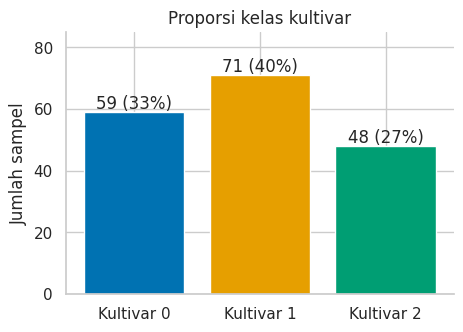

In [ ]:
# Visualisasi 1: proporsi kelas
fig, ax = plt.subplots(figsize=(5, 3.4))
cnt = df["kultivar"].value_counts().sort_index()
ax.bar(cnt.index, cnt.values, color=[PAL[k] for k in cnt.index])
for i, v in enumerate(cnt.values): ax.text(i, v + 1, f"{v} ({100*v/len(df):.0f}%)", ha="center")
ax.set_ylabel("Jumlah sampel"); ax.set_title("Proporsi kelas kultivar"); ax.set_ylim(0, 85)
plt.savefig("../figures/01_proporsi_kelas.png", dpi=150, bbox_inches="tight"); plt.show()

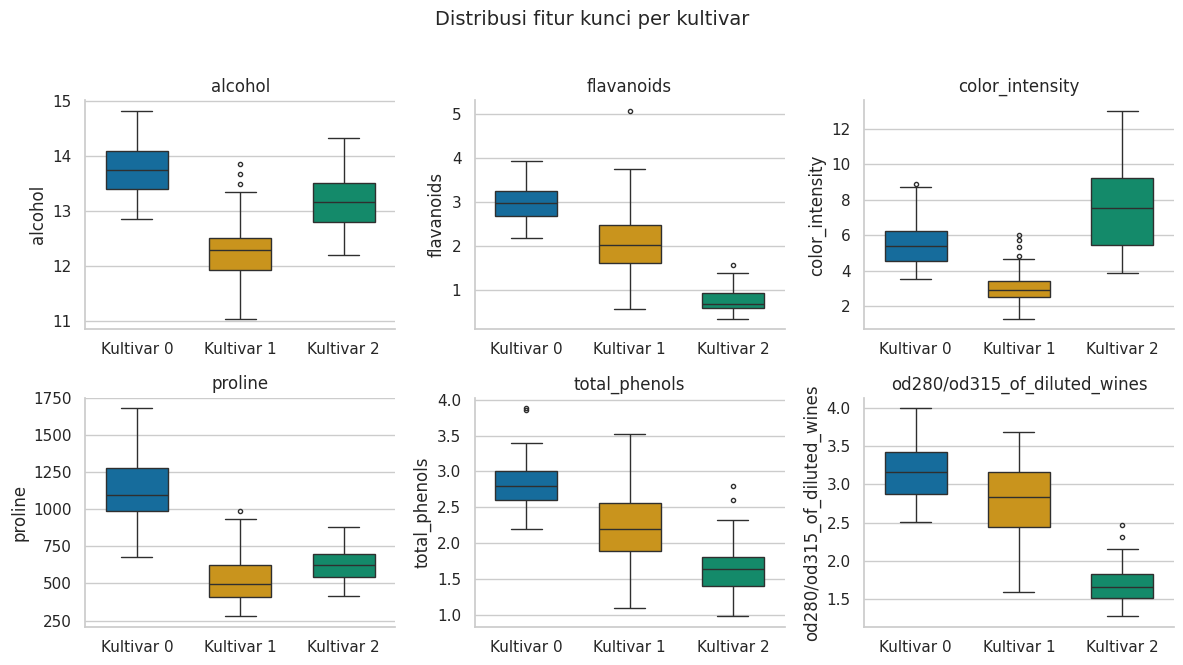

In [ ]:
# Visualisasi 2: distribusi 6 fitur utama per kultivar
kunci = ["alcohol", "flavanoids", "color_intensity", "proline", "total_phenols", "od280/od315_of_diluted_wines"]
fig, axes = plt.subplots(2, 3, figsize=(12, 6.5))
for ax, f in zip(axes.ravel(), kunci):
    sns.boxplot(data=df, x="kultivar", y=f, order=list(PAL), palette=PAL, ax=ax, width=.6, fliersize=3)
    ax.set_xlabel(""); ax.set_title(f)
plt.suptitle("Distribusi fitur kunci per kultivar", y=1.02, fontsize=14)
plt.tight_layout(); plt.savefig("../figures/02_boxplot_fitur_kunci.png", dpi=150, bbox_inches="tight"); plt.show()

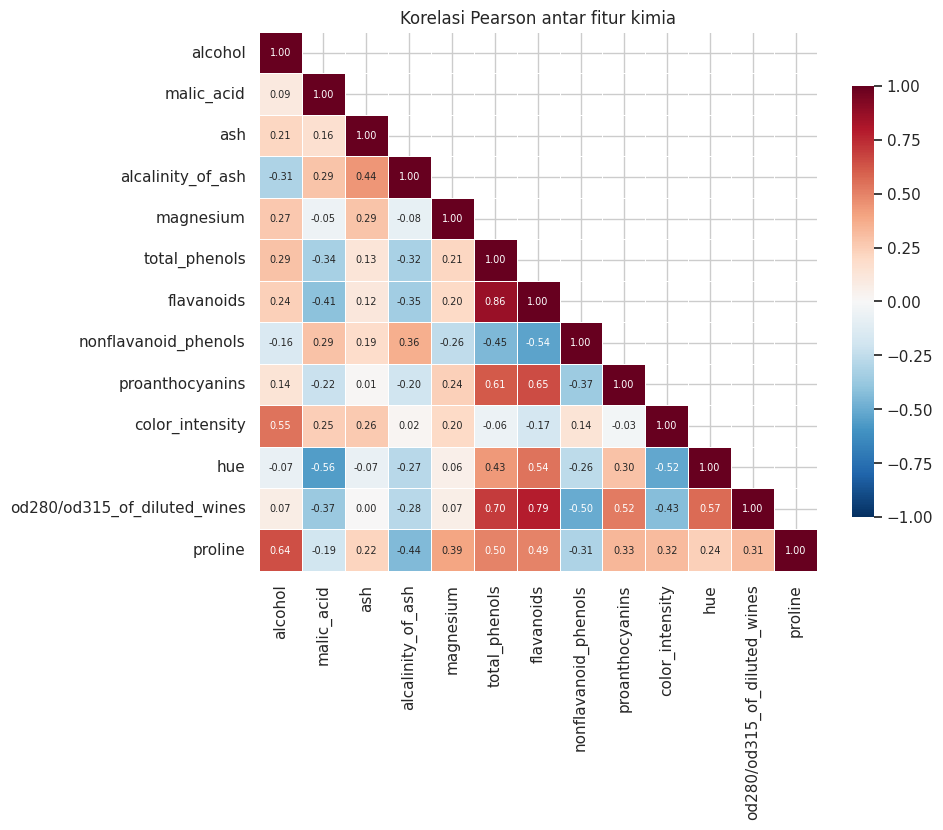

5 pasangan fitur dengan korelasi terkuat:
flavanoids                    total_phenols    0.865
od280/od315_of_diluted_wines  flavanoids       0.787
                              total_phenols    0.700
proanthocyanins               flavanoids       0.653
proline                       alcohol          0.644
dtype: float64


In [ ]:
# Visualisasi 3: matriks korelasi antar fitur
corr = df[fitur].corr()
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, mask=mask, cmap="RdBu_r", center=0, vmin=-1, vmax=1, annot=True, fmt=".2f", annot_kws={"size": 7},
            linewidths=.5, cbar_kws={"shrink": .8}, ax=ax)
ax.set_title("Korelasi Pearson antar fitur kimia")
plt.savefig("../figures/03_korelasi.png", dpi=150, bbox_inches="tight"); plt.show()

pairs = corr.where(~mask & (corr != 1)).stack().sort_values(key=abs, ascending=False).head(5)
print("5 pasangan fitur dengan korelasi terkuat:"); print(pairs.round(3))

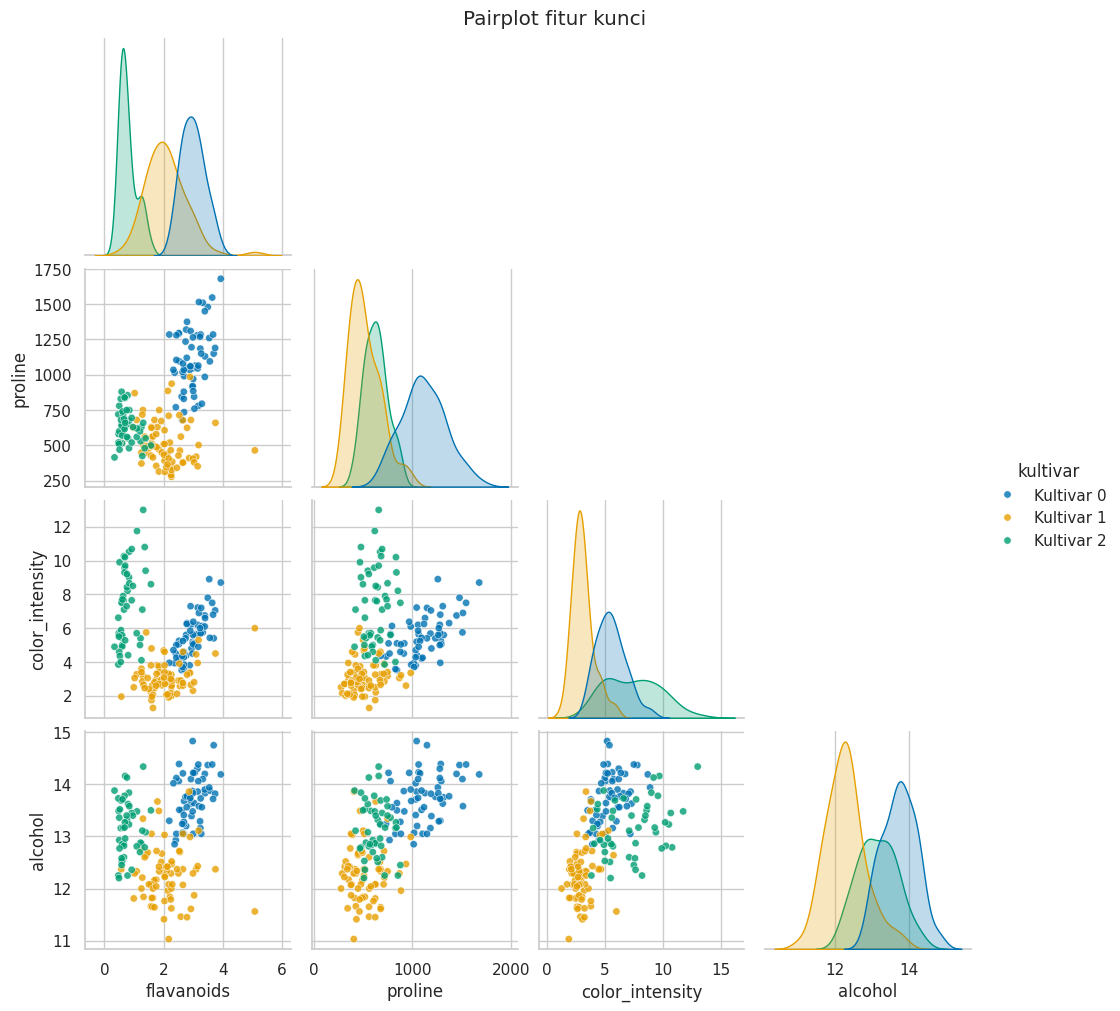

In [ ]:
# Visualisasi 4: pairplot 4 fitur paling informatif secara visual
g = sns.pairplot(df, vars=["flavanoids", "proline", "color_intensity", "alcohol"], hue="kultivar",
                 palette=PAL, corner=True, plot_kws={"s": 28, "alpha": .8}, diag_kind="kde")
g.figure.suptitle("Pairplot fitur kunci", y=1.01)
g.savefig("../figures/04_pairplot.png", dpi=150, bbox_inches="tight"); plt.show()

**Temuan EDA** (diverifikasi dari keluaran di atas):
- Data bersih: 178 sampel, 13 fitur numerik, tidak ada *missing value* maupun duplikat.
- Kelas cukup seimbang (33% / 40% / 27%), cukup untuk memakai *stratified split* tanpa teknik *resampling*.
- Skala fitur sangat berbeda (mis. `proline` ratusan sampai ribuan, `hue` sekitar 1), sehingga **scaling wajib** untuk model berbasis jarak (KNN, SVM, K-Means, PCA).
- `flavanoids`, `total_phenols`, dan `od280/od315` berkorelasi kuat positif (kelompok senyawa fenolik), sehingga ada **multikolinearitas**. Ini penting saat membaca koefisien regresi logistik.
- Kultivar sudah tampak terpisah pada `flavanoids`, `proline`, dan `color_intensity` (boxplot dan pairplot).
- Ada sedikit outlier (mis. `magnesium`, `malic_acid`). Nilainya masih masuk akal secara kimia sehingga **tidak dibuang**.

---
# Tahap 3. Preprocessing

Prinsip: semua langkah yang *belajar dari data* (imputasi, scaling) dimasukkan ke dalam **`Pipeline`** sehingga hanya "belajar" dari data latih pada tiap lipatan cross-validation, sehingga tidak ada *data leakage*.

- **Split 80/20 dengan `stratify=y`**: proporsi kelas terjaga di data latih dan uji. Data uji disimpan dan baru dipakai **sekali** di evaluasi akhir.
- **Imputasi median**: dataset ini tidak punya missing value, tetapi imputer tetap dipasang agar pipeline tangguh bila dipakai pada data baru.
- **Encoding**: tidak diperlukan karena semua fitur numerik dan label sudah berupa 0/1/2.
- **StandardScaler**: untuk model berbasis jarak dan margin.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print("Train:", X_train.shape, "| Test:", X_test.shape)
prop = pd.DataFrame({"semua": y.value_counts(normalize=True).sort_index(),
                     "train": y_train.value_counts(normalize=True).sort_index(),
                     "test":  y_test.value_counts(normalize=True).sort_index()}).round(3)
print("\nProporsi kelas setelah stratified split:"); print(prop)

def buat_pipeline(clf, scale=True):
    langkah = [("imputer", SimpleImputer(strategy="median"))]
    if scale: langkah.append(("scaler", StandardScaler()))
    langkah.append(("clf", clf))
    return Pipeline(langkah)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

Train: (142, 13) | Test: (36, 13)

Proporsi kelas setelah stratified split:
        semua  train   test
target                     
0       0.331  0.331  0.333
1       0.399  0.401  0.389
2       0.270  0.268  0.278


---
# Tahap 4. Supervised Learning

## 4.1 Perbandingan algoritma dengan 5-fold stratified cross-validation (hanya pada data latih)

| Model | Peran |
|---|---|
| `DummyClassifier` (kelas mayoritas) | **Baseline** paling sederhana |
| Logistic Regression | Model linear, koefisien mudah ditafsirkan |
| K-Nearest Neighbors | Berbasis jarak, non-parametrik |
| SVM (kernel RBF) | Margin maksimal, kuat untuk data kecil berdimensi menengah |
| Random Forest | Ensemble pohon, memberi *feature importance* |

In [ ]:
models = {
    "Baseline (Dummy)": buat_pipeline(DummyClassifier(strategy="most_frequent"), scale=False),
    "Logistic Regression": buat_pipeline(LogisticRegression(max_iter=2000, random_state=SEED)),
    "KNN (k=5)": buat_pipeline(KNeighborsClassifier(n_neighbors=5)),
    "SVM (RBF)": buat_pipeline(SVC(random_state=SEED)),
    "Random Forest": buat_pipeline(RandomForestClassifier(n_estimators=300, random_state=SEED), scale=False),
}
rows = []
for nama, m in models.items():
    s = cross_validate(m, X_train, y_train, cv=cv, scoring=["accuracy", "f1_macro"])
    rows.append({"Model": nama,
                 "acc_mean": s["test_accuracy"].mean(), "acc_std": s["test_accuracy"].std(),
                 "f1_mean": s["test_f1_macro"].mean(), "f1_std": s["test_f1_macro"].std()})
cv_df = pd.DataFrame(rows).set_index("Model")
tabel = pd.DataFrame({"Akurasi (mean ± std)": cv_df.apply(lambda r: f"{r.acc_mean:.3f} ± {r.acc_std:.3f}", axis=1),
                      "F1-macro (mean ± std)": cv_df.apply(lambda r: f"{r.f1_mean:.3f} ± {r.f1_std:.3f}", axis=1)})
tabel

,Akurasi (mean ± std),F1-macro (mean ± std)
Model,,
Baseline (Dummy),0.401 ± 0.010,0.191 ± 0.003
Logistic Regression,0.979 ± 0.028,0.980 ± 0.027
KNN (k=5),0.951 ± 0.035,0.951 ± 0.036
SVM (RBF),0.986 ± 0.017,0.986 ± 0.017
Random Forest,0.979 ± 0.028,0.979 ± 0.029


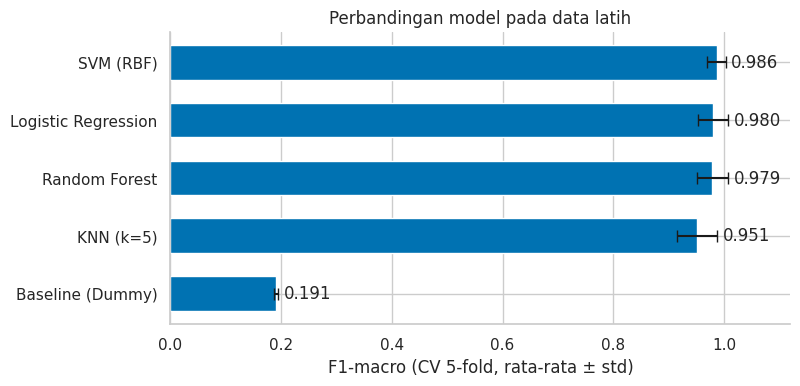

Model terbaik berdasarkan F1-macro CV: SVM (RBF)


In [ ]:
fig, ax = plt.subplots(figsize=(8, 3.8))
order = cv_df.sort_values("f1_mean").index
ax.barh(order, cv_df.loc[order, "f1_mean"], xerr=cv_df.loc[order, "f1_std"], color="#0072B2", capsize=4, height=.6)
for i, n in enumerate(order): ax.text(cv_df.loc[n, "f1_mean"] + cv_df.loc[n, "f1_std"] + .01, i, f"{cv_df.loc[n,'f1_mean']:.3f}", va="center")
ax.set_xlim(0, 1.12); ax.set_xlabel("F1-macro (CV 5-fold, rata-rata ± std)"); ax.set_title("Perbandingan model pada data latih")
plt.savefig("../figures/05_perbandingan_model.png", dpi=150, bbox_inches="tight"); plt.show()
print("Model terbaik berdasarkan F1-macro CV:", cv_df["f1_mean"].idxmax())

**Pembacaan hasil.** Semua model non-baseline jauh melampaui baseline (~0,40 akurasi). Selisih antar model non-baseline **kecil dibanding simpangan baku** antar lipatan, sehingga peringkat tidak boleh dibaca berlebihan: pada data sekecil ini model sederhana (regresi logistik) hampir setara dengan model kompleks (Random Forest). SVM memiliki rata-rata F1-macro tertinggi sehingga dipilih untuk *tuning*.

## 4.2 Hyperparameter tuning SVM (GridSearchCV, hanya pada data latih)

In [ ]:
param_grid = {"clf__C": [0.1, 1, 10, 100],
              "clf__kernel": ["linear", "rbf"],
              "clf__gamma": ["scale", 0.001, 0.01, 0.1]}
gs = GridSearchCV(buat_pipeline(SVC(random_state=SEED)), param_grid, cv=cv, scoring="f1_macro", n_jobs=-1)
gs.fit(X_train, y_train)
print("Parameter terbaik :", gs.best_params_)
print(f"F1-macro CV terbaik: {gs.best_score_:.3f}")
hasil = pd.DataFrame(gs.cv_results_)[["param_clf__kernel", "param_clf__C", "param_clf__gamma", "mean_test_score", "std_test_score"]]
hasil.sort_values("mean_test_score", ascending=False).head(8).round(4).reset_index(drop=True)

Parameter terbaik : {'clf__C': 100, 'clf__gamma': 0.01, 'clf__kernel': 'rbf'}
F1-macro CV terbaik: 0.994


,param_clf__kernel,param_clf__C,param_clf__gamma,mean_test_score,std_test_score
0,rbf,100.0,0.01,0.9939,0.0121
1,rbf,10.0,0.1,0.9927,0.0147
2,rbf,10.0,scale,0.9927,0.0147
3,rbf,100.0,scale,0.9927,0.0147
4,rbf,100.0,0.1,0.9927,0.0147
5,rbf,1.0,0.1,0.9865,0.0167
6,rbf,1.0,scale,0.9865,0.0167
7,linear,1.0,scale,0.9863,0.0274


In [ ]:
# Estimasi kinerja yang jujur: nested CV (tuning di lipatan dalam, evaluasi di lipatan luar) pada data latih
outer = StratifiedKFold(n_splits=5, shuffle=True, random_state=7)
nested = cross_val_score(GridSearchCV(buat_pipeline(SVC(random_state=SEED)), param_grid, cv=cv, scoring="f1_macro"),
                         X_train, y_train, cv=outer, scoring="f1_macro", n_jobs=-1)
print(f"Nested CV F1-macro: {nested.mean():.3f} ± {nested.std():.3f}")
print(f"(skor 'best_score_' GridSearch {gs.best_score_:.3f} sedikit optimistis karena dipilih sebagai maksimum)")

Nested CV F1-macro: 0.973 ± 0.025
(skor 'best_score_' GridSearch 0.994 sedikit optimistis karena dipilih sebagai maksimum)


## 4.3 Evaluasi akhir pada data uji (dilakukan **sekali saja**)

In [ ]:
best_model = gs.best_estimator_
y_pred = best_model.predict(X_test)
print(f"Akurasi test  : {accuracy_score(y_test, y_pred):.3f}")
print(f"F1-macro test : {f1_score(y_test, y_pred, average='macro'):.3f}\n")
names = ["Kultivar 0", "Kultivar 1", "Kultivar 2"]
print(classification_report(y_test, y_pred, target_names=names, digits=3))

Akurasi test  : 0.972
F1-macro test : 0.971

              precision    recall  f1-score   support

  Kultivar 0      1.000     1.000     1.000        12
  Kultivar 1      0.933     1.000     0.966        14
  Kultivar 2      1.000     0.900     0.947        10

    accuracy                          0.972        36
   macro avg      0.978     0.967     0.971        36
weighted avg      0.974     0.972     0.972        36



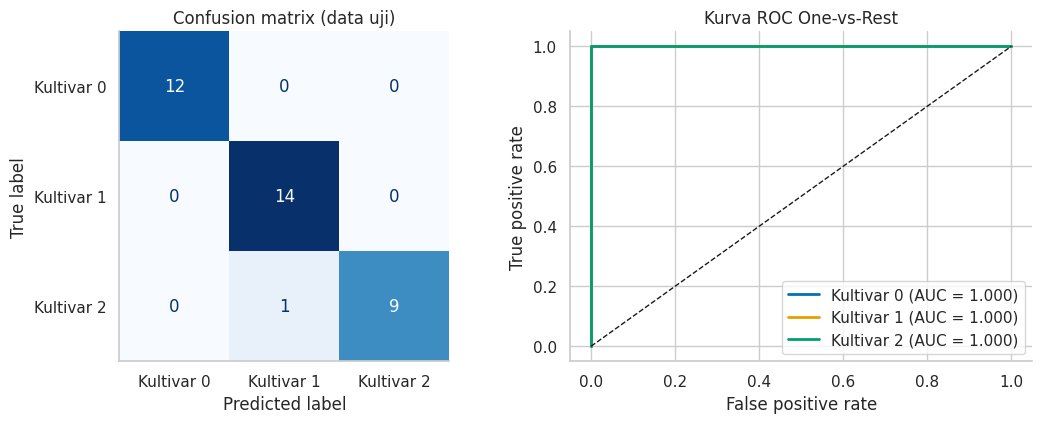

AUC macro (OvR): 1.000
Sampel salah klasifikasi (indeks asli): [134]


In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.4))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=names, cmap="Blues", ax=ax[0], colorbar=False)
ax[0].set_title("Confusion matrix (data uji)"); ax[0].grid(False)

# ROC One-vs-Rest dari skor keputusan SVM
skor = best_model.decision_function(X_test)
Y = label_binarize(y_test, classes=[0, 1, 2])
for k, nm in enumerate(names):
    fpr, tpr, _ = roc_curve(Y[:, k], skor[:, k]); ax[1].plot(fpr, tpr, color=PAL[nm], lw=2, label=f"{nm} (AUC = {auc(fpr, tpr):.3f})")
ax[1].plot([0, 1], [0, 1], "k--", lw=1); ax[1].set_xlabel("False positive rate"); ax[1].set_ylabel("True positive rate")
ax[1].set_title("Kurva ROC One-vs-Rest"); ax[1].legend(loc="lower right")
plt.tight_layout(); plt.savefig("../figures/06_evaluasi_akhir.png", dpi=150, bbox_inches="tight"); plt.show()
auc_macro = np.mean([auc(*roc_curve(Y[:, k], skor[:, k])[:2]) for k in range(3)])
print(f"AUC macro (OvR): {auc_macro:.3f}")
print("Sampel salah klasifikasi (indeks asli):", list(X_test.index[y_test.values != y_pred]))

## 4.4 Pemeriksaan kecurigaan *leakage* (hasil mendekati sempurna)

Akurasi sekitar 97-99% patut dicurigai. Dua pemeriksaan dilakukan:
1. **Uji label teracak (permutation test)**: bila pipeline benar, label yang diacak harus menghasilkan kinerja ≈ peluang acak (~0,33-0,40).
2. **Audit prosedur**: scaling/imputasi berada di dalam `Pipeline`, *tuning* hanya memakai data latih, data uji dipakai sekali.

In [ ]:
rng = np.random.RandomState(SEED)
y_acak = pd.Series(rng.permutation(y_train.values), index=y_train.index)
s_acak = cross_val_score(buat_pipeline(SVC(C=gs.best_params_['clf__C'], kernel=gs.best_params_['clf__kernel'], gamma=gs.best_params_['clf__gamma'])),
                         X_train, y_acak, cv=cv, scoring="accuracy")
print(f"Akurasi CV dengan label diacak: {s_acak.mean():.3f} ± {s_acak.std():.3f}  (peluang acak ≈ {y_train.value_counts(normalize=True).max():.2f} s.d. 0.33)")
print("Kesimpulan: kinerja runtuh ke level acak, sehingga skor tinggi berasal dari sinyal kimia nyata, bukan kebocoran.")

Akurasi CV dengan label diacak: 0.381 ± 0.063  (peluang acak ≈ 0.40 s.d. 0.33)
Kesimpulan: kinerja runtuh ke level acak, sehingga skor tinggi berasal dari sinyal kimia nyata, bukan kebocoran.


---
# Tahap 5. Unsupervised Learning

Tahap ini **tidak memakai label** saat membentuk PCA dan klaster. Label hanya dipakai setelahnya untuk validasi. Seluruh fitur di-*scale* karena PCA dan K-Means sensitif terhadap skala.

## 5.1 PCA

Variansi dijelaskan per komponen (PC1-PC5): [36.2 19.2 11.1  7.1  6.6] %
PC1+PC2 = 55.4%  |  PC1-PC3 = 66.5%
Jumlah PC untuk >= 80% variansi: 5  |  untuk >= 95%: 10


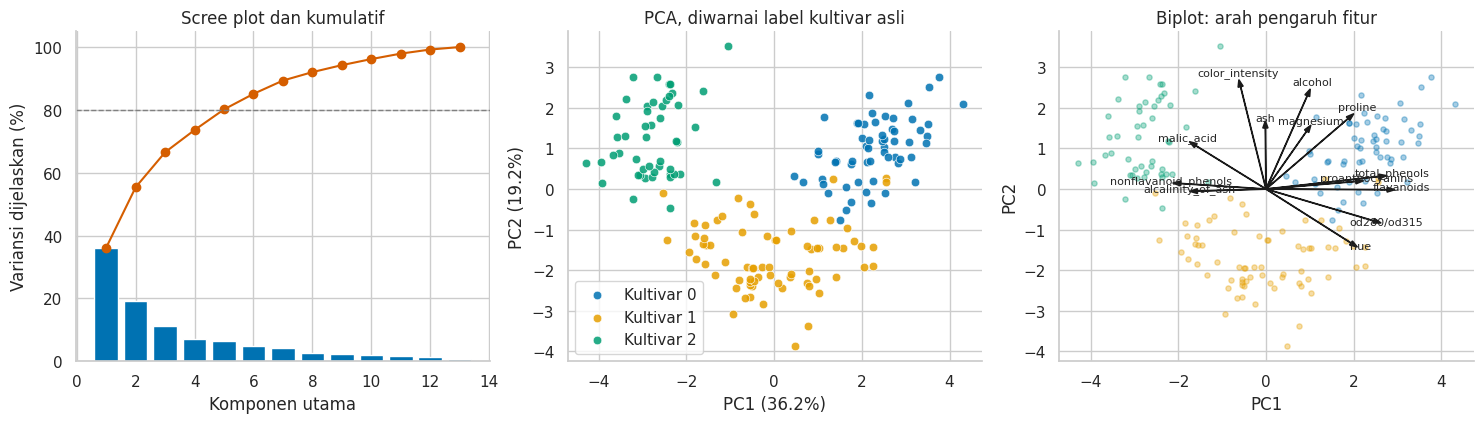

In [ ]:
Xs = StandardScaler().fit_transform(X)
pca = PCA(random_state=SEED).fit(Xs)
evr = pca.explained_variance_ratio_
cum = evr.cumsum()
Z = pca.transform(Xs)
print("Variansi dijelaskan per komponen (PC1-PC5):", (evr[:5]*100).round(1), "%")
print(f"PC1+PC2 = {cum[1]*100:.1f}%  |  PC1-PC3 = {cum[2]*100:.1f}%")
print(f"Jumlah PC untuk >= 80% variansi: {int(np.argmax(cum >= .8)) + 1}  |  untuk >= 95%: {int(np.argmax(cum >= .95)) + 1}")

fig, ax = plt.subplots(1, 3, figsize=(15, 4.4))
ax[0].bar(range(1, 14), evr*100, color="#0072B2"); ax[0].plot(range(1, 14), cum*100, "o-", color="#D55E00")
ax[0].axhline(80, ls="--", c="gray", lw=1); ax[0].set_xlabel("Komponen utama"); ax[0].set_ylabel("Variansi dijelaskan (%)"); ax[0].set_title("Scree plot dan kumulatif")
for nm in names:
    m = (df["kultivar"] == nm).values; ax[1].scatter(Z[m, 0], Z[m, 1], s=38, color=PAL[nm], label=nm, alpha=.85, edgecolor="white", lw=.5)
ax[1].set_xlabel(f"PC1 ({evr[0]*100:.1f}%)"); ax[1].set_ylabel(f"PC2 ({evr[1]*100:.1f}%)"); ax[1].set_title("PCA, diwarnai label kultivar asli"); ax[1].legend()
# Biplot: arah kontribusi fitur
load = pca.components_[:2].T * np.sqrt(pca.explained_variance_[:2])
for nm in names:
    m = (df["kultivar"] == nm).values; ax[2].scatter(Z[m, 0], Z[m, 1], s=14, color=PAL[nm], alpha=.35)
for i, f in enumerate(fitur):
    ax[2].arrow(0, 0, load[i, 0]*3, load[i, 1]*3, color="k", width=.01, head_width=.12)
    ax[2].text(load[i, 0]*3.35, load[i, 1]*3.35, f.replace("od280/od315_of_diluted_wines", "od280/od315"), fontsize=8, ha="center")
ax[2].set_xlabel("PC1"); ax[2].set_ylabel("PC2"); ax[2].set_title("Biplot: arah pengaruh fitur")
plt.tight_layout(); plt.savefig("../figures/07_pca.png", dpi=150, bbox_inches="tight"); plt.show()

In [ ]:
loadings = pd.DataFrame(pca.components_[:3].T, index=fitur, columns=["PC1", "PC2", "PC3"])
print("Fitur dengan loading terbesar (nilai absolut):")
for pc in ["PC1", "PC2"]:
    print(f"\n{pc}:"); print(loadings[pc].reindex(loadings[pc].abs().sort_values(ascending=False).index).head(5).round(3).to_string())

Fitur dengan loading terbesar (nilai absolut):

PC1:
flavanoids                      0.423
total_phenols                   0.395
od280/od315_of_diluted_wines    0.376
proanthocyanins                 0.313
nonflavanoid_phenols           -0.299

PC2:
color_intensity    0.530
alcohol            0.484
proline            0.365
ash                0.316
magnesium          0.300


## 5.2 Pemilihan jumlah klaster K (elbow dan silhouette)

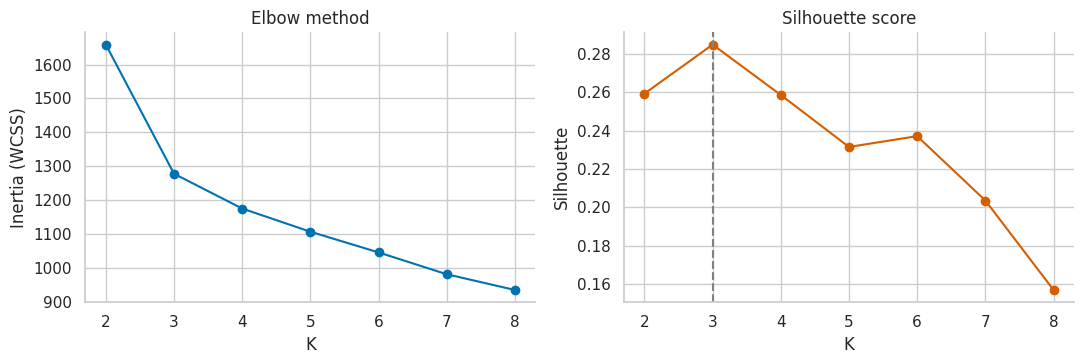

 K  inertia  silhouette
 2   1658.8       0.259
 3   1277.9       0.285
 4   1175.4       0.259
 5   1107.0       0.232
 6   1046.0       0.237
 7    981.6       0.204
 8    935.2       0.157

Silhouette tertinggi pada K = 3


In [ ]:
Ks = range(2, 9)
inertia, sil = [], []
for k in Ks:
    km_ = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(Xs)
    inertia.append(km_.inertia_); sil.append(silhouette_score(Xs, km_.labels_))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(list(Ks), inertia, "o-", color="#0072B2"); ax[0].set_xlabel("K"); ax[0].set_ylabel("Inertia (WCSS)"); ax[0].set_title("Elbow method")
ax[1].plot(list(Ks), sil, "o-", color="#D55E00"); ax[1].set_xlabel("K"); ax[1].set_ylabel("Silhouette"); ax[1].set_title("Silhouette score")
ax[1].axvline(list(Ks)[int(np.argmax(sil))], ls="--", c="gray")
plt.tight_layout(); plt.savefig("../figures/08_pemilihan_K.png", dpi=150, bbox_inches="tight"); plt.show()
print(pd.DataFrame({"K": list(Ks), "inertia": np.round(inertia, 1), "silhouette": np.round(sil, 3)}).to_string(index=False))
print(f"\nSilhouette tertinggi pada K = {list(Ks)[int(np.argmax(sil))]}")

**Pemilihan K = 3.** Silhouette mencapai puncak pada K=3, dan kurva elbow melandai setelah K=3. Pemilihan ini didasarkan pada kriteria internal tanpa memakai label, sehingga tidak sirkular, dan kebetulan konsisten dengan jumlah kultivar.

## 5.3 K-Means (K=3) dan perbandingan dengan label asli

In [ ]:
km = KMeans(n_clusters=3, n_init=20, random_state=SEED).fit(Xs)
df["klaster_kmeans"] = km.labels_
print(f"Silhouette : {silhouette_score(Xs, km.labels_):.3f}")
print(f"ARI        : {adjusted_rand_score(y, km.labels_):.3f}")
print(f"NMI        : {normalized_mutual_info_score(y, km.labels_):.3f}")
print(f"Homogeneity: {homogeneity_score(y, km.labels_):.3f} | Completeness: {completeness_score(y, km.labels_):.3f}\n")
ct = pd.crosstab(df["kultivar"], df["klaster_kmeans"].rename("klaster"))
display(ct)
# Peta klaster -> kultivar mayoritas (hanya untuk menghitung kesalahan penempatan)
peta = ct.idxmax(axis=0).str.replace("Kultivar ", "").astype(int).to_dict()
salah = int((df["klaster_kmeans"].map(peta) != y).sum())
print(f"Sampel yang jatuh di klaster 'bukan miliknya': {salah} dari {len(df)} ({100*salah/len(df):.1f}%)")

Silhouette : 0.285
ARI        : 0.897
NMI        : 0.876
Homogeneity: 0.879 | Completeness: 0.873



klaster,0,1,2
kultivar,,,
Kultivar 0,0,0,59
Kultivar 1,65,3,3
Kultivar 2,0,48,0


Sampel yang jatuh di klaster 'bukan miliknya': 6 dari 178 (3.4%)


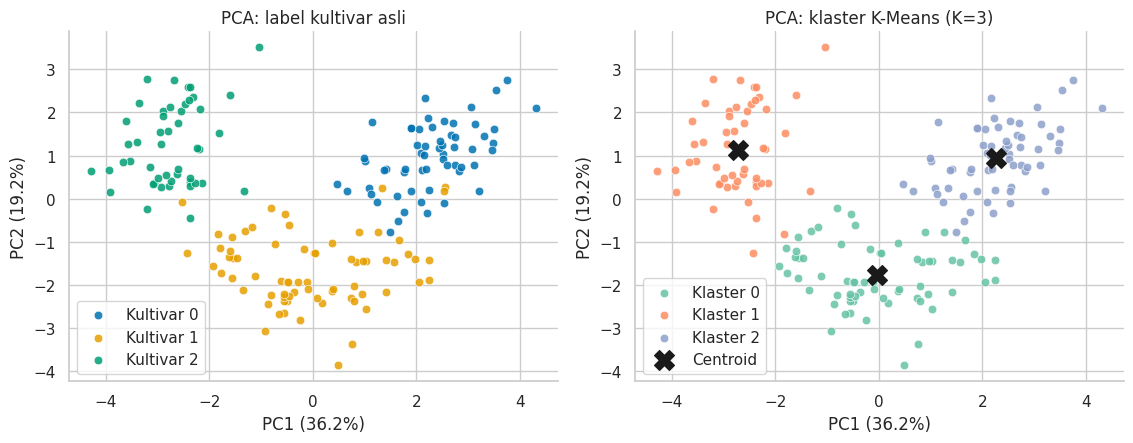

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.6))
for nm in names:
    m = (df["kultivar"] == nm).values; ax[0].scatter(Z[m, 0], Z[m, 1], s=38, color=PAL[nm], label=nm, alpha=.85, edgecolor="white", lw=.5)
ax[0].set_title("PCA: label kultivar asli"); ax[0].legend()
cl_col = sns.color_palette("Set2", 3)
for c in range(3):
    m = km.labels_ == c; ax[1].scatter(Z[m, 0], Z[m, 1], s=38, color=cl_col[c], label=f"Klaster {c}", alpha=.85, edgecolor="white", lw=.5)
cent = pca.transform(km.cluster_centers_); ax[1].scatter(cent[:, 0], cent[:, 1], marker="X", s=200, c="k", label="Centroid")
ax[1].set_title("PCA: klaster K-Means (K=3)"); ax[1].legend()
for a in ax: a.set_xlabel(f"PC1 ({evr[0]*100:.1f}%)"); a.set_ylabel(f"PC2 ({evr[1]*100:.1f}%)")
plt.tight_layout(); plt.savefig("../figures/09_kmeans_vs_label.png", dpi=150, bbox_inches="tight"); plt.show()

In [ ]:
# Profil kimia tiap klaster (dalam satuan asli) untuk interpretasi
profil = df.groupby("klaster_kmeans")[["alcohol", "flavanoids", "color_intensity", "proline", "total_phenols", "hue", "malic_acid"]].mean().round(2)
profil["n"] = df["klaster_kmeans"].value_counts().sort_index()
profil

,alcohol,flavanoids,color_intensity,proline,total_phenols,hue,malic_acid,n
klaster_kmeans,,,,,,,,
0,12.25,2.05,2.97,510.17,2.25,1.06,1.90,65
1,13.13,0.82,7.23,619.06,1.68,0.69,3.31,51
2,13.68,3.00,5.45,1100.23,2.85,1.07,2.00,62


## 5.4 Hierarchical Clustering (Ward) dan pengujian skala

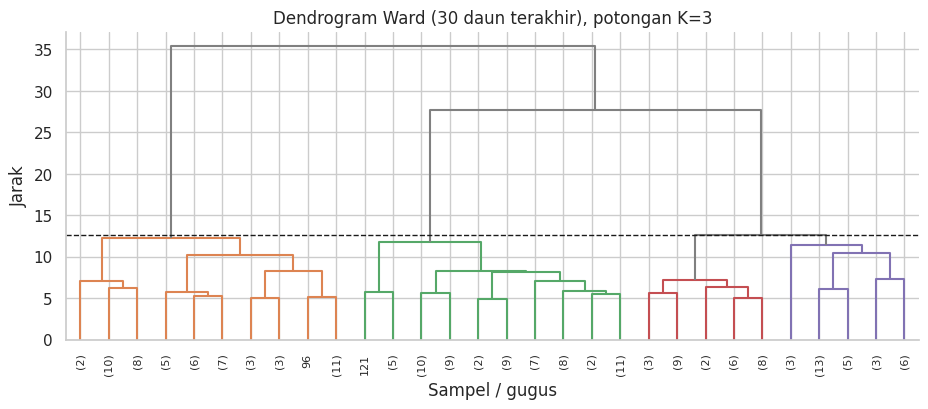

,ARI,NMI,Silhouette
Metode,,,
Hierarchical (ward),0.790,0.786,0.277
Hierarchical (average),-0.005,0.018,0.158
Hierarchical (complete),0.577,0.614,0.204
Hierarchical (single),-0.007,0.035,0.183
K-Means tanpa scaling,0.371,0.429,0.571
K-Means (scaled) [utama],0.897,0.876,0.285


In [ ]:
Zl = linkage(Xs, method="ward")
fig, ax = plt.subplots(figsize=(11, 4))
dendrogram(Zl, truncate_mode="lastp", p=30, leaf_rotation=90, leaf_font_size=8, color_threshold=Zl[-3, 2], above_threshold_color="gray", ax=ax)
ax.axhline(Zl[-3, 2] - 0.01, ls="--", c="k", lw=1); ax.set_title("Dendrogram Ward (30 daun terakhir), potongan K=3"); ax.set_ylabel("Jarak"); ax.set_xlabel("Sampel / gugus")
plt.savefig("../figures/10_dendrogram.png", dpi=150, bbox_inches="tight"); plt.show()

hasil = []
for lk in ["ward", "average", "complete", "single"]:
    lab = AgglomerativeClustering(n_clusters=3, linkage=lk).fit_predict(Xs)
    hasil.append({"Metode": f"Hierarchical ({lk})", "ARI": adjusted_rand_score(y, lab), "NMI": normalized_mutual_info_score(y, lab), "Silhouette": silhouette_score(Xs, lab)})
# K-Means TANPA scaling sebagai pembanding (apa yang tidak berhasil)
lab_ns = KMeans(n_clusters=3, n_init=20, random_state=SEED).fit_predict(X)
hasil.append({"Metode": "K-Means tanpa scaling", "ARI": adjusted_rand_score(y, lab_ns), "NMI": normalized_mutual_info_score(y, lab_ns), "Silhouette": silhouette_score(X, lab_ns)})
hasil.append({"Metode": "K-Means (scaled) [utama]", "ARI": adjusted_rand_score(y, km.labels_), "NMI": normalized_mutual_info_score(y, km.labels_), "Silhouette": silhouette_score(Xs, km.labels_)})
pd.DataFrame(hasil).set_index("Metode").round(3)

---
# Tahap 6. Interpretasi: fitur apa yang paling berpengaruh?

Empat sudut pandang dibandingkan agar kesimpulan tidak bergantung pada satu metode:
1. **Uji univariat** (ANOVA F, hanya data latih),
2. **Koefisien regresi logistik** (data ter-*scale*),
3. **Importance Random Forest** (penurunan impurity),
4. **Permutation importance** pada model SVM terbaik (data uji, hanya interpretasi, tidak dipakai memilih model).

In [ ]:
# 1. ANOVA F (train)
F, p = f_classif(X_train, y_train)
imp = pd.DataFrame({"anova_F": F}, index=fitur)

# 2. Logistic regression (train, scaled): rata-rata |koefisien| lintas kelas
lr = buat_pipeline(LogisticRegression(max_iter=2000, random_state=SEED)).fit(X_train, y_train)
coef = pd.DataFrame(lr.named_steps["clf"].coef_, columns=fitur, index=names).T
imp["logreg_|coef|"] = coef.abs().mean(axis=1)

# 3. Random Forest (train)
rf = RandomForestClassifier(n_estimators=500, random_state=SEED).fit(X_train, y_train)
imp["rf_importance"] = rf.feature_importances_

# 4. Permutation importance model SVM tuned (test)
pi = permutation_importance(best_model, X_test, y_test, n_repeats=50, random_state=SEED, scoring="accuracy")
imp["perm_importance"] = pi.importances_mean

rank = imp.rank(ascending=False).astype(int)
rank["rata2_peringkat"] = rank.mean(axis=1)
rank = rank.sort_values("rata2_peringkat")
print("Peringkat tiap metode (1 = paling berpengaruh):")
rank

Peringkat tiap metode (1 = paling berpengaruh):


,anova_F,logreg_|coef|,rf_importance,perm_importance,rata2_peringkat
flavanoids,1,3,2,2,2.00
proline,2,2,3,1,2.00
color_intensity,4,1,1,10,4.00
alcohol,5,4,4,3,4.00
od280/od315_of_diluted_wines,3,8,5,4,5.00
hue,6,7,6,8,6.75
alcalinity_of_ash,9,5,11,5,7.50
total_phenols,7,11,7,7,8.00
proanthocyanins,10,10,9,6,8.75
malic_acid,8,9,10,13,10.00


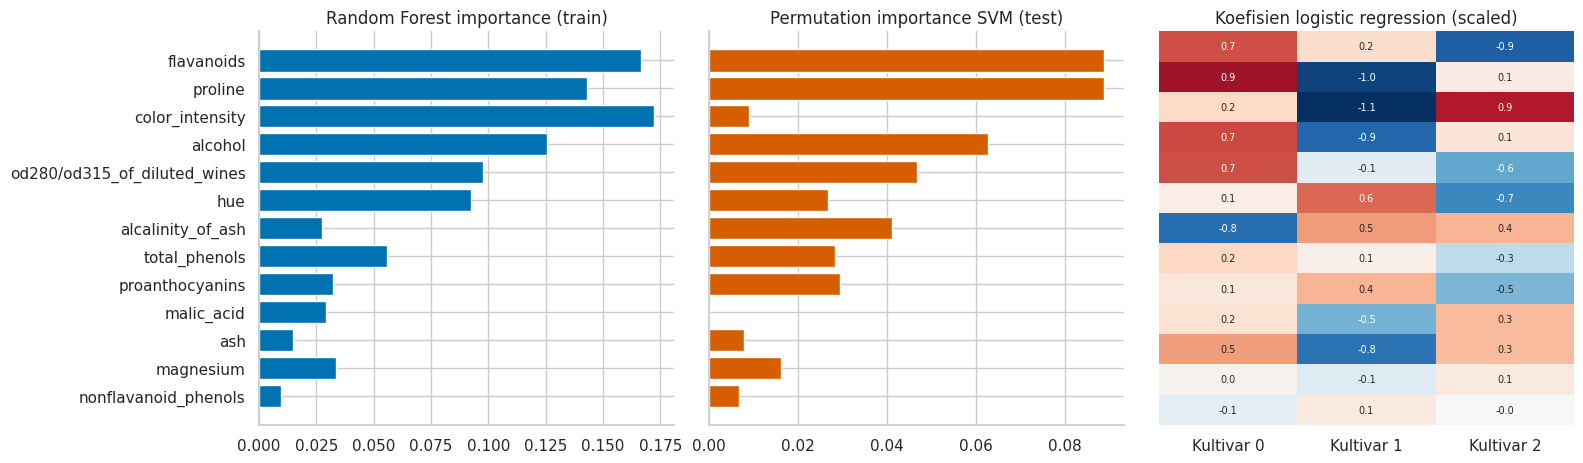

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.8))
ordr = rank.index
rfi = imp.loc[ordr, "rf_importance"].iloc[::-1]
ax[0].barh(rfi.index, rfi.values, color="#0072B2"); ax[0].set_title("Random Forest importance (train)")
pim = imp.loc[ordr, "perm_importance"].iloc[::-1]
ax[1].barh(pim.index, pim.values, color="#D55E00"); ax[1].set_title("Permutation importance SVM (test)"); ax[1].set_yticklabels([])
sns.heatmap(coef.loc[ordr], cmap="RdBu_r", center=0, annot=True, fmt=".1f", annot_kws={"size": 7}, cbar=False, ax=ax[2])
ax[2].set_title("Koefisien logistic regression (scaled)"); ax[2].set_yticklabels([])
plt.tight_layout(); plt.savefig("../figures/11_feature_importance.png", dpi=150, bbox_inches="tight"); plt.show()

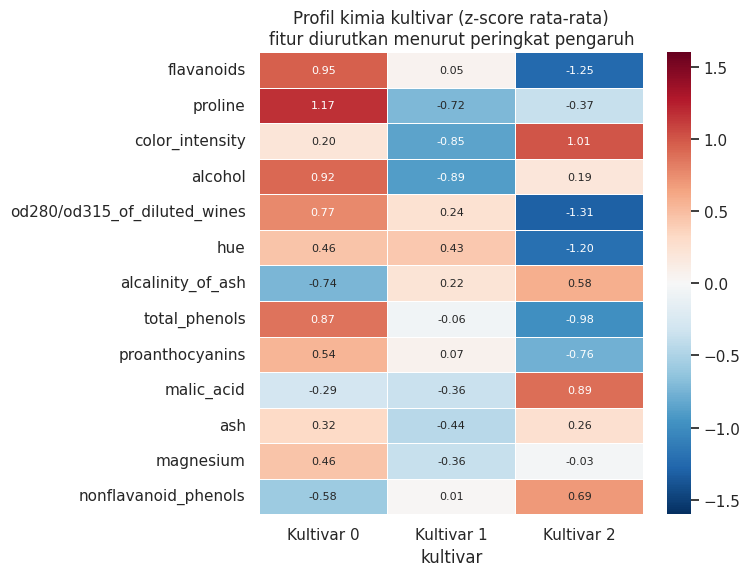

,alcohol,flavanoids,total_phenols,color_intensity,proline,hue,od280/od315_of_diluted_wines,malic_acid
kultivar,,,,,,,,
Kultivar 0,13.74,2.98,2.84,5.53,1115.71,1.06,3.16,2.01
Kultivar 1,12.28,2.08,2.26,3.09,519.51,1.06,2.79,1.93
Kultivar 2,13.15,0.78,1.68,7.40,629.90,0.68,1.68,3.33


In [ ]:
# Profil kimia tiap kultivar dalam z-score (rata-rata kultivar relatif terhadap seluruh sampel)
z = (df[fitur] - df[fitur].mean()) / df[fitur].std()
prof = z.groupby(df["kultivar"]).mean().T.loc[rank.index]
fig, ax = plt.subplots(figsize=(6.2, 6))
sns.heatmap(prof, cmap="RdBu_r", center=0, vmin=-1.6, vmax=1.6, annot=True, fmt=".2f", annot_kws={"size": 8}, linewidths=.5, ax=ax)
ax.set_title("Profil kimia kultivar (z-score rata-rata)\nfitur diurutkan menurut peringkat pengaruh"); ax.set_ylabel("")
plt.savefig("../figures/12_profil_kultivar.png", dpi=150, bbox_inches="tight"); plt.show()
raw = df.groupby("kultivar")[["alcohol", "flavanoids", "total_phenols", "color_intensity", "proline", "hue", "od280/od315_of_diluted_wines", "malic_acid"]].mean().round(2)
raw

## Apakah hasilnya masuk akal secara biologis?

**Konsistensi antar metode.** `flavanoids` dan `proline` konsisten berada di peringkat teratas (rata-rata peringkat 2,0), diikuti `color_intensity`, `alcohol`, dan `od280/od315`. Sebaliknya `magnesium`, `ash`, `malic_acid`, dan `nonflavanoid_phenols` berpengaruh kecil. Ada satu ketidaksesuaian yang perlu dijelaskan: `color_intensity` peringkat 1 di regresi logistik dan Random Forest, tetapi peringkat 10 di *permutation importance*. Penyebabnya, informasinya **redundan** dengan fitur lain (mis. `flavanoids`, `hue`), sehingga saat satu fitur diacak, SVM masih bisa memakai fitur lain. Ini bukti bahwa tidak ada satu ukuran importance yang final.

**Profil kimia tiap kultivar** (rata-rata, dari heatmap z-score dan tabel di atas):

| Kultivar | Ciri kimia utama |
|---|---|
| 0 | `proline` sangat tinggi (≈1116 vs 520 dan 630), `alcohol` tinggi (13,7), `flavanoids` tinggi (3,0), `od280/od315` tinggi (3,2), alkalinitas abu rendah |
| 1 | `alcohol` terendah (12,3), `color_intensity` terendah (3,1), `proline` rendah (≈520), fenolik sedang |
| 2 | `flavanoids` terendah (0,78), `total_phenols` dan `od280/od315` terendah (1,7), `hue` terendah (0,68), `color_intensity` dan `malic_acid` tertinggi (7,4 dan 3,3), `nonflavanoid_phenols` tertinggi |

**Penalaran biologis (hipotesis yang konsisten dengan literatur, bukan bukti kausal):**
1. **Senyawa fenolik (flavonoid, total fenol, OD280)**. Flavonoid disintesis lewat jalur fenilpropanoid/flavonoid yang aktivitasnya dikendalikan genotip, sehingga kadar fenolik adalah ciri kultivar yang wajar (Waterhouse, 2002). Absorbansi pada 280 nm secara kimia memang menangkap cincin fenolik, sehingga korelasi `od280/od315` dengan `flavanoids` (r≈0,79) dan `total_phenols` bukan kebetulan. Itulah sebabnya **PC1 (36,2% variansi) adalah "sumbu fenolik"**: loading terbesar dari `flavanoids`, `total_phenols`, `od280/od315`, `proanthocyanins`.
2. **Prolin**. Prolin adalah asam amino utama dalam buah anggur dan akumulasinya berbeda antar kultivar serta dipengaruhi kematangan dan stres air (Stines et al., 2000). Ia juga relatif tidak dimetabolisme ragi pada kondisi anaerob sehingga bertahan di anggur jadi, dan wajar menjadi "penanda kultivar" yang kuat.
3. **Warna (`color_intensity`, `hue`)**. Warna anggur merah ditentukan antosianin dan kopigmentasinya dengan flavonoid (Boulton, 2001). Kultivar 2 unik: warna pekat tetapi flavonoid rendah, yaitu kombinasi yang menjadi pembeda tajam dari dua kultivar lain.
4. **Alkohol** mencerminkan kadar gula saat panen (kematangan), yang dipengaruhi kultivar sekaligus iklim dan waktu panen. Pengaruhnya sebagian **bersifat lingkungan**, bukan murni genetik.
5. **PC2 (19,2%)** didominasi `color_intensity`, `alcohol`, `proline`, yaitu sumbu "kematangan/konsentrasi". Kedua sumbu PCA cocok dengan peringkat importance model supervised, yaitu dua metode berbeda menunjuk fitur yang sama.
6. **Fitur mineral** (`magnesium`, `ash`) berpengaruh rendah. Ini masuk akal karena kadar mineral lebih ditentukan tanah daripada kultivar.

**Batasan interpretasi.** Semua sampel berasal dari satu wilayah, sehingga pembeda kultivar bercampur dengan efek kebun/tahun panen (*confounding*). Importance menunjukkan fitur yang berguna untuk **memprediksi**, bukan penyebab biologis. Kesimpulan di atas adalah hipotesis yang masuk akal dan perlu uji lanjut.

**Referensi**
- Forina, M., et al. (1991). *PARVUS: An Extendible Package for Data Exploration, Classification and Correlation.* Institute of Pharmaceutical and Food Analysis and Technologies, Genoa. (sumber asli Wine dataset; salinan di UCI ML Repository, Dua & Graff, 2019)
- Pedregosa, F., et al. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825-2830.
- Waterhouse, A. L. (2002). Wine phenolics. *Annals of the New York Academy of Sciences, 957*, 21-36.
- Stines, A. P., et al. (2000). Proline and arginine accumulation in developing berries of *Vitis vinifera* L. in Australian vineyards. *Australian Journal of Grape and Wine Research, 6*, 150-158.
- Boulton, R. (2001). The copigmentation of anthocyanins and its role in the color of red wine: a critical review. *American Journal of Enology and Viticulture, 52*, 67-87.

---
# Tahap 7. Diskusi dan Keterbatasan

**Kelemahan data**
- **Ukuran kecil** (178 sampel, hanya 36 sampel uji): satu sampel salah = ±2,8 poin akurasi, sehingga selisih antar model tidak signifikan secara statistik.
- **Asal data sempit**: tiga kultivar dari satu wilayah Italia dengan satu panen pada periode tertentu. Variasi tahun panen, terroir, dan metode pembuatan anggur tidak terwakili. Model belum tentu berlaku untuk wilayah lain.
- Label kultivar anonim (`class_0/1/2`) di versi scikit-learn, sehingga pencocokan ke nama varietas tertentu tidak dilakukan.
- Fitur hanya 13 parameter bulk; profil metabolomik penuh (LC-MS/NMR) akan jauh lebih kaya.

**Risiko bias, leakage, overfitting**
- *Leakage*: dicegah dengan `Pipeline`, *stratified split*, tuning hanya pada data latih, dan uji label-acak. Catatan: PCA/K-Means pada Tahap 5 memakai *scaling* seluruh sampel, yang aman karena tahap itu murni deskriptif (tidak memprediksi data baru).
- *Overfitting*: dipantau lewat CV dan *nested* CV. Selisih skor CV dan skor uji kecil. Tuning grid kecil membatasi risiko seleksi berlebih.
- Dataset ini terkenal "mudah" (benchmark klasik), sehingga skor tinggi tidak boleh dianggap bukti bahwa klasifikasi kultivar anggur secara umum mudah.
- Korelasi antar fitur fenolik membuat nilai koefisien individual tidak stabil. Pengaruh sebaiknya dibaca per kelompok senyawa.

**Apa yang tidak berhasil / catatan negatif**
- Model kompleks (Random Forest) **tidak** lebih baik daripada model sederhana (regresi logistik, SVM). KNN paling rendah di antara model non-baseline.
- K-Means **tanpa scaling** buruk (ARI 0,37 vs 0,90) karena `proline` (skala ribuan) mendominasi jarak. Menariknya silhouette-nya justru **tinggi (0,57)**: silhouette hanya mengukur keterpisahan geometris, bukan kebenaran biologis, sehingga bisa menyesatkan bila skala fitur tidak seragam.
- Hierarchical Ward (ARI 0,79) di bawah K-Means (0,90). Linkage *average* dan *single* gagal total (ARI ≈ 0, efek *chaining*), dan *complete* hanya 0,58.
- Clustering tidak sempurna: 6 dari 178 sampel (3,4%) jatuh di klaster lain, semuanya dari kultivar 1 yang profil kimianya berada di antara dua kultivar lain.
- Pada data uji, 1 sampel kultivar 2 salah diprediksi sebagai kultivar 1. Kurva ROC (AUC macro 1,000) menunjukkan skor kelas benarnya tetap terurut baik, sehingga kesalahan ini lebih terkait batas keputusan daripada ketidakmampuan memisahkan kelas.

**Saran pengembangan**
- Validasi eksternal pada kumpulan data wine dari wilayah/tahun lain, dan *repeated CV* untuk selang kepercayaan.
- Uji signifikansi antar model (mis. *paired test* pada hasil CV berulang) dan kalibrasi probabilitas.
- Coba *feature selection* (mis. 3-5 fitur teratas) untuk menguji apakah panel kimia ringkas cukup untuk *authentication* rutin.
- Gabungkan data spektral (NIR/NMR) atau metabolomik untuk resolusi biologis lebih tinggi.

---
# Kesimpulan

1. **Profil kimia cukup untuk memprediksi kultivar.** SVM (RBF) yang di-*tuning* mencapai akurasi uji 97,2% dan F1-macro 0,971 (hanya 1 dari 36 sampel salah), jauh di atas baseline 40%. Estimasi nested CV (0,973) selaras dengan skor uji, dan uji label-acak runtuh ke level peluang, sehingga tidak ada tanda *leakage*.
2. **Model sederhana hampir setara dengan model kompleks**. Selisih antar model berada dalam satu simpangan baku.
3. **Pembeda utama ketiga kultivar:** `flavanoids` dan fenolik terkait, `proline`, `color_intensity`, dan `alcohol`. Kultivar 0 kaya prolin, alkohol, dan flavonoid. Kultivar 1 rendah alkohol dan warna. Kultivar 2 rendah flavonoid tetapi berwarna pekat.
4. **Tanpa label pun struktur tiga kelompok muncul**: PC1+PC2 menjelaskan 55,4% variansi, K=3 dipilih oleh silhouette, dan K-Means menghasilkan ARI 0,90 terhadap kultivar asli. Scaling terbukti krusial.
5. Hasil ini berlaku untuk data dari satu wilayah, ukuran kecil, dan perlu validasi eksternal.

Ringkasan numerik yang dihitung otomatis dari notebook:

In [ ]:
kesimpulan = f"""
RINGKASAN HASIL
- Data: {df.shape[0]} sampel, {len(fitur)} fitur, 3 kultivar, tanpa missing value.
- Supervised: baseline akurasi CV {cv_df.loc['Baseline (Dummy)','acc_mean']:.3f}; model terbaik (SVM tuned, {gs.best_params_})
  F1-macro CV {gs.best_score_:.3f}, nested CV {nested.mean():.3f} ± {nested.std():.3f};
  uji akhir: akurasi {accuracy_score(y_test, y_pred):.3f}, F1-macro {f1_score(y_test, y_pred, average='macro'):.3f}, AUC macro {auc_macro:.3f}.
- Uji label teracak: akurasi {s_acak.mean():.3f} (≈ peluang acak) -> tidak ada indikasi leakage.
- Unsupervised: PC1+PC2 menjelaskan {cum[1]*100:.1f}% variansi; K=3 (silhouette {silhouette_score(Xs, km.labels_):.3f});
  K-Means vs kultivar: ARI {adjusted_rand_score(y, km.labels_):.3f}, NMI {normalized_mutual_info_score(y, km.labels_):.3f}.
- 5 fitur teratas (rata-rata peringkat): {', '.join(rank.index[:5])}.
"""
print(kesimpulan)


RINGKASAN HASIL
- Data: 178 sampel, 13 fitur, 3 kultivar, tanpa missing value.
- Supervised: baseline akurasi CV 0.401; model terbaik (SVM tuned, {'clf__C': 100, 'clf__gamma': 0.01, 'clf__kernel': 'rbf'})
  F1-macro CV 0.994, nested CV 0.973 ± 0.025;
  uji akhir: akurasi 0.972, F1-macro 0.971, AUC macro 1.000.
- Uji label teracak: akurasi 0.381 (≈ peluang acak) -> tidak ada indikasi leakage.
- Unsupervised: PC1+PC2 menjelaskan 55.4% variansi; K=3 (silhouette 0.285);
  K-Means vs kultivar: ARI 0.897, NMI 0.876.
- 5 fitur teratas (rata-rata peringkat): flavanoids, proline, color_intensity, alcohol, od280/od315_of_diluted_wines.

